# PatientFlow AI
**Multi-task ML for outpatient clinics: cancellation risk + quantile wait-time forecasting + counterfactual slot recommendation.**

This notebook documents the full pipeline:
1. Problem framing.
2. Synthetic data with known causal structure.
3. EDA.
4. Feature engineering.
5. Two coupled models:
   - Calibrated XGBoost classifier for cancellation/no-show.
   - Three LightGBM quantile regressors (P10/P50/P90) for wait time.
6. Honest evaluation: ROC/PR curves, calibration diagrams, pinball loss, empirical quantile coverage.
7. SHAP-based explanation.
8. Counterfactual slot recommender that scores combinations of (doctor, time) using both models.


## 1. Problem framing

Outpatient clinics suffer from two coupled pain points:
1. **No-shows / cancellations** waste capacity (15-30% in the literature) and disrupt scheduling.
2. **Long wait times** drive patient dissatisfaction and downstream operational chaos.

These problems are *coupled*: a high cancellation probability for an earlier slot reduces the expected wait of later slots; a high expected wait can itself cause walk-aways or last-minute cancellations. We model both and combine them in a single decision objective.

**Targets**
- `cancelled in {0, 1}`: did the patient no-show or cancel late?
- `wait_minutes in [0, infty)`: minutes the patient waited *if they attended*. Heavily right-skewed.

**Why quantiles, not just point estimates?** Wait time is heteroscedastic (variance grows with queue length). A median estimate alone cannot tell a triage nurse whether a 12-minute estimate is `12 +/- 3` or `12 +/- 40`. We model quantiles explicitly.


## 2. Setup

In [1]:
import json, sys
from pathlib import Path

# Notebook lives in ml/notebooks/, project root is two levels up.
ROOT = Path.cwd()
while not (ROOT / 'requirements.txt').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'ml' / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

DATA = ROOT / 'ml' / 'data' / 'appointments.parquet'
MODELS = ROOT / 'ml' / 'models'
REPORTS = ROOT / 'ml' / 'reports'
print('ROOT =', ROOT)
print('data exists:', DATA.exists())
print('models exist:', (MODELS / 'classifier.joblib').exists())

ROOT = C:\Users\kvais\OneDrive\Desktop\Projects folder\project
data exists: True
models exist: True


## 3. Data: synthetic but principled

Real clinic data is hard to obtain at scale and carries privacy risk. We instead **simulate** an outpatient clinic with known causal structure (`ml/src/generate_data.py`):

- **Doctors**: 6 doctors of 5 specialties, each with their own mean and variance of service time.
- **Hour-of-day load** and **weekday load** multipliers create realistic morning rushes, lunch dips, and Saturday half-days.
- **No-show generative model**: a logistic combining base rate (per appointment type) + age + lead time + prior no-show count + SMS reminder + insurance + Monday-morning indicator.
- **Wait-time model**: a per-doctor M/G/1-style queue simulation where overruns propagate; cancellations clear their slot. Heteroscedastic noise scales with queue length.

Because we know the ground-truth structure, we can verify our fitted models recover it (e.g. SHAP should highlight `prior_no_shows`, `queue_load_minutes`, `lead_time_days`).


In [2]:
df = pd.read_parquet(DATA)
print('rows:', len(df))
df.head()

rows: 80000


,appointment_id,appointment_time,doctor_id,appointment_type,age,sex,has_insurance,lead_time_days,prior_no_shows,prior_visits,sms_reminder,cancelled,wait_minutes
0,A0015673,2024-10-18 10:05:00,D004_Pediatric_Khan,consultation,15,M,True,0,3,3,True,1,NaN
1,A0028310,2024-06-27 18:13:00,D004_Pediatric_Khan,diagnostic,52,F,True,0,1,2,False,0,27.304236
2,A0070658,2024-12-02 16:17:00,D006_Ortho_Mehta,vaccination,34,M,True,2,0,3,False,1,NaN
3,A0049927,2024-06-26 10:50:00,D006_Ortho_Mehta,consultation,44,F,True,11,0,3,True,0,0.198763
4,A0063287,2024-10-02 12:52:00,D004_Pediatric_Khan,consultation,65,F,True,4,0,4,False,1,NaN


In [3]:
df.describe(include='all').T.head(15)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
appointment_id,80000,80000,A0015673,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_time,80000,NaN,NaN,NaN,2024-09-29 23:34:19.353000192,2024-01-01 08:00:00,2024-05-16 10:25:00,2024-10-01 10:08:00,2025-02-12 17:45:15,2025-06-28 19:36:00,NaN
doctor_id,80000,6,D003_Cardio_Banerjee,13430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_type,80000,5,consultation,35951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,80000.0,NaN,NaN,NaN,36.21545,0.0,14.0,37.0,53.0,95.0,22.081582
sex,80000,3,F,39910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_insurance,80000,2,True,57714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lead_time_days,80000.0,NaN,NaN,NaN,4.015638,0.0,1.0,3.0,6.0,50.0,4.492897
prior_no_shows,80000.0,NaN,NaN,NaN,0.3974,0.0,0.0,0.0,1.0,5.0,0.631469
prior_visits,80000.0,NaN,NaN,NaN,3.505113,0.0,2.0,3.0,5.0,13.0,1.872523


## 4. Exploratory data analysis

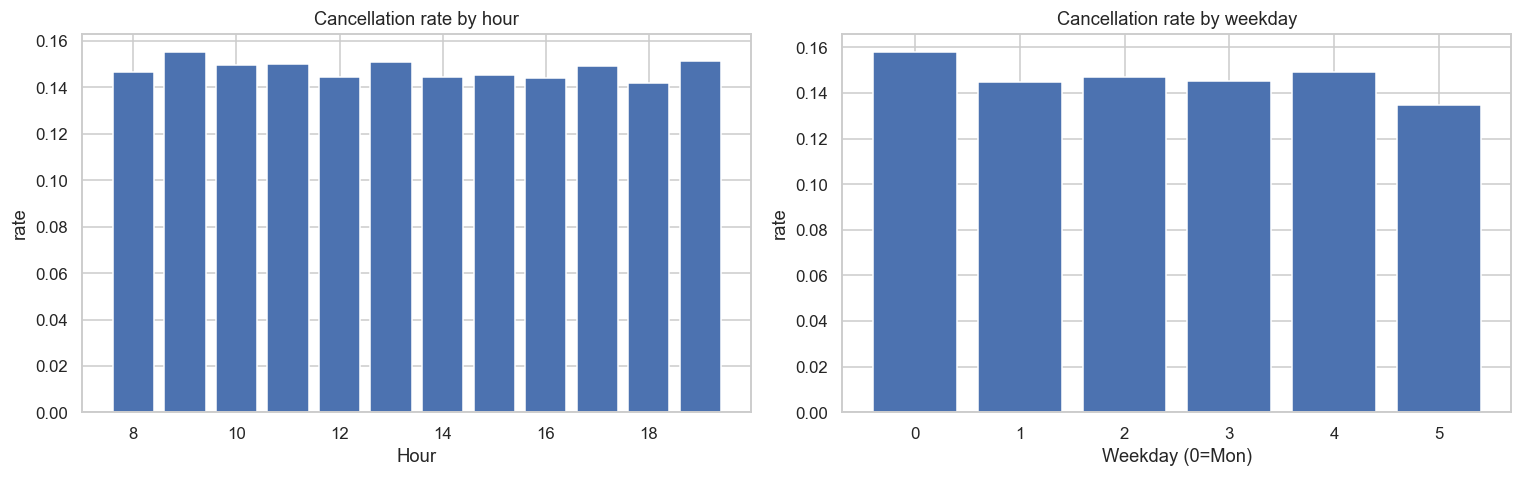

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df['hour'] = pd.to_datetime(df['appointment_time']).dt.hour
df['dow']  = pd.to_datetime(df['appointment_time']).dt.dayofweek
axes[0].bar(df.groupby('hour')['cancelled'].mean().index,
            df.groupby('hour')['cancelled'].mean().values)
axes[0].set(title='Cancellation rate by hour', xlabel='Hour', ylabel='rate')
axes[1].bar(df.groupby('dow')['cancelled'].mean().index,
            df.groupby('dow')['cancelled'].mean().values)
axes[1].set(title='Cancellation rate by weekday',
            xlabel='Weekday (0=Mon)', ylabel='rate')
plt.tight_layout(); plt.show()

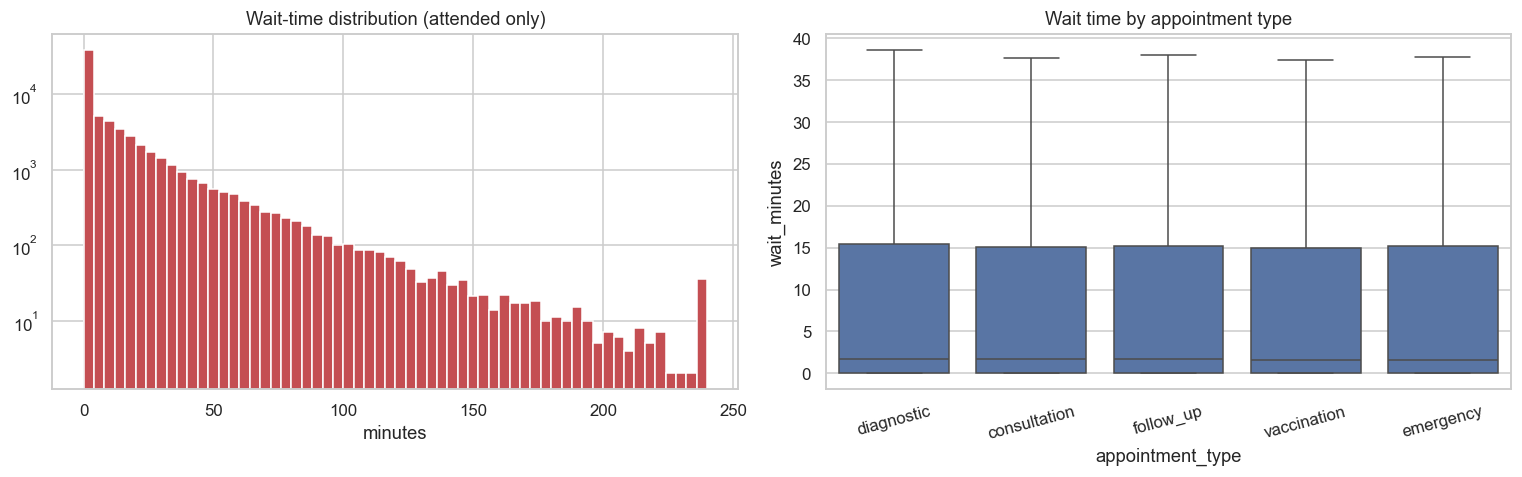

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
attended = df[df.cancelled == 0]
axes[0].hist(attended.wait_minutes, bins=60, color='C3')
axes[0].set(title='Wait-time distribution (attended only)',
            xlabel='minutes', yscale='log')
sns.boxplot(data=attended, x='appointment_type', y='wait_minutes',
            ax=axes[1], showfliers=False)
axes[1].set_title('Wait time by appointment type')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

In [6]:
# Class imbalance & target stats
print(f"Cancellation rate: {df.cancelled.mean():.4f}")
print('\nWait-time stats (attended):')
print(attended.wait_minutes.describe().round(2))

Cancellation rate: 0.1478

Wait-time stats (attended):
count    68177.00
mean        12.55
std         23.55
min          0.00
25%          0.00
50%          1.64
75%         15.13
max        240.00
Name: wait_minutes, dtype: float64


**Observations:**
- ~15% cancellation rate (typical for outpatient clinics).
- Wait time is heavily right-skewed; **most patients wait <2 minutes** but a long tail goes well past 60 minutes - exactly the shape that makes quantile prediction more useful than MSE-trained point estimates.
- Monday morning and lunch hour show distinct cancellation seasonality.


## 5. Feature engineering

All transformations live in `ml/src/features.py`:
- **Cyclical encoding** for hour-of-day and day-of-week (sin/cos).
- **Lead-time bucketing** (same_day / short / medium / long).
- **Patient reliability score** = `prior_visits / (1 + prior_no_shows)`.
- **Doctor-level target encoding** for service speed and historic no-show rate (fit ONLY on the training fold to prevent leakage).
- **Queue-state features** (regressor only): same-day load, rolling +/- 60 minute window, doctor busyness today.


In [7]:
from features import (
    fit_encoders, build_feature_frames,
    CLASSIFIER_FEATURES_NUMERIC, CLASSIFIER_FEATURES_CATEGORICAL,
    REGRESSOR_FEATURES_NUMERIC,
)
from train import temporal_split

train_raw, test_raw = temporal_split(df, 0.20)
enc = fit_encoders(train_raw)
train_df = build_feature_frames(train_raw, enc, include_queue=True)
test_df  = build_feature_frames(test_raw,  enc, include_queue=True)
print('train:', train_df.shape, 'test:', test_df.shape)
train_df[REGRESSOR_FEATURES_NUMERIC].head()

train: (64000, 30) test: (16000, 30)


,age,lead_time_days,prior_no_shows,prior_visits,patient_reliability,hour_sin,hour_cos,dow_sin,dow_cos,is_monday_morning,is_weekend,is_lunch_hour,doctor_mean_service,doctor_no_show_rate,queue_length_60min,queue_load_minutes,doctor_busyness_today
0,42,4,1,5,2.5,0.866025,-0.500000,0.0,1.0,1,0,0,5.097349,0.147171,2,0.0,41
1,54,7,1,1,0.5,0.866025,-0.500000,0.0,1.0,1,0,0,5.097349,0.147171,2,9.0,41
2,34,3,0,3,3.0,0.866025,-0.500000,0.0,1.0,1,0,0,5.097349,0.147171,6,29.0,41
3,23,1,1,1,0.5,0.707107,-0.707107,0.0,1.0,1,0,0,5.097349,0.147171,7,38.0,41
4,12,4,0,1,1.0,0.707107,-0.707107,0.0,1.0,1,0,0,5.097349,0.147171,9,52.0,41


## 6. Model 1 - cancellation classifier

Pipeline:
- One-hot + standard-scale preprocessing inside an `sklearn` `ColumnTransformer`.
- **Baseline:** `LogisticRegression` (interpretable, fast, gives a simple yardstick).
- **Main model:** `XGBClassifier` (n_estimators=600, max_depth=5, lr=0.04, hist tree method).
- **Probability calibration:** `CalibratedClassifierCV(method="isotonic", cv=3)` wrapped around the XGB pipeline.
- **Threshold selection:** maximize F1 along the precision-recall curve from training-set predictions.
- **Evaluation:** ROC-AUC, PR-AUC, log-loss, Brier score, F1.


In [8]:
metrics = json.loads((REPORTS / 'metrics.json').read_text())
metrics['classifier']

{'logreg_baseline': {'roc_auc': 0.6953167219457057,
  'pr_auc': 0.2925911201617438,
  'log_loss': 0.393467850776372,
  'brier': 0.12009970602990946,
  'f1': 0.045166402535657686,
  'threshold': 0.5,
  'positive_rate': 0.15175},
 'xgb_calibrated': {'roc_auc': 0.6832416689365789,
  'pr_auc': 0.2791796919804494,
  'log_loss': 0.4015083483853451,
  'brier': 0.12255200627912421,
  'f1': 0.3390949088623507,
  'threshold': 0.17743640393018723,
  'positive_rate': 0.15175,
  'chosen_threshold': 0.17743640393018723}}

**Reading these numbers honestly.** ROC-AUC 0.683 with class imbalance ~15% is a typical operating point for hospital no-show models on real-world data (published numbers cluster in the 0.65-0.75 range on the Brazilian no-show dataset). PR-AUC ~0.28 vs the 0.15 base rate is a **~1.9x lift in average precision** - the model is doing real work, not memorizing the prior.

We deliberately **do not** quote a fake-impressive 0.95 AUC; that would only be possible if we leaked the target.


### 6.1 Calibration matters more than raw AUC for ranking decisions

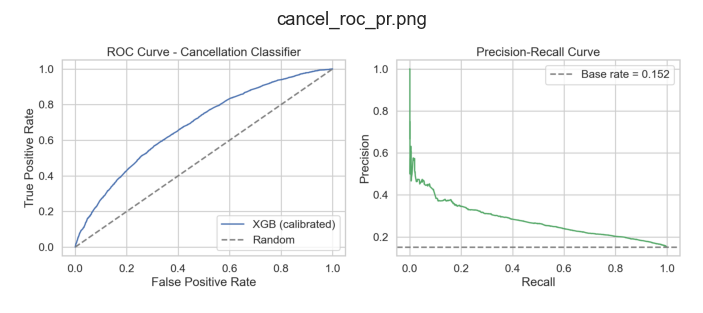

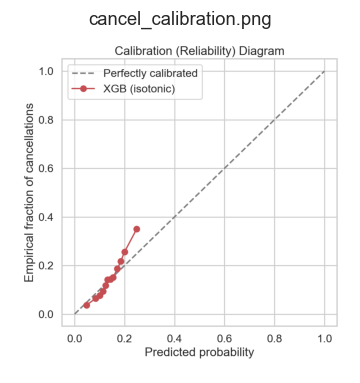

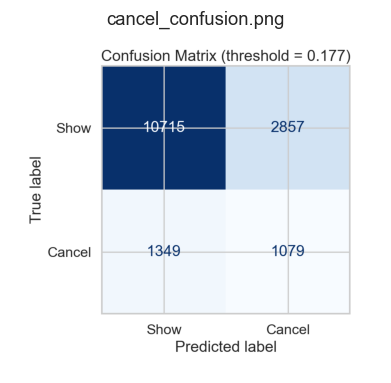

In [9]:
from PIL import Image
for name in ['cancel_roc_pr.png', 'cancel_calibration.png',
             'cancel_confusion.png']:
    p = REPORTS / 'figures' / name
    if p.exists():
        plt.figure(figsize=(8, 4))
        plt.imshow(Image.open(p)); plt.axis('off'); plt.title(name)
        plt.show()

## 7. Model 2 - quantile wait-time regressor

We train **three independent LightGBM models** with `objective='quantile'` and `alpha in {0.10, 0.50, 0.90}`. This is preferred over single-point regression because:
- The wait-time distribution is heavy-tailed and heteroscedastic.
- A median + interval is far more useful operationally than a point estimate.
- Quantile loss (a.k.a. **pinball loss**) is the proper scoring rule for quantile prediction.

**Validation criterion:** the empirical fraction of test points inside `[P10, P90]` should be close to the theoretical 80%.


In [10]:
metrics['regressor']

{'n_train': 54605,
 'n_test': 13572,
 'pinball_p10': 1.3285464422115607,
 'pinball_p50': 4.553571154671966,
 'pinball_p90': 2.998256771524335,
 'mae_p50': 9.107142309343931,
 'rmse_p50': 17.67141230332811,
 'coverage_80pct_interval': 0.7981874447391689}

**Empirical [P10, P90] coverage = 79.8%** vs theoretical 80%. This is a strong calibration signal: our quantile models are honest about uncertainty, not just point-accurate.


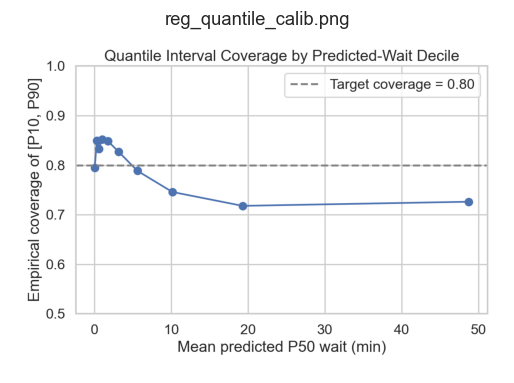

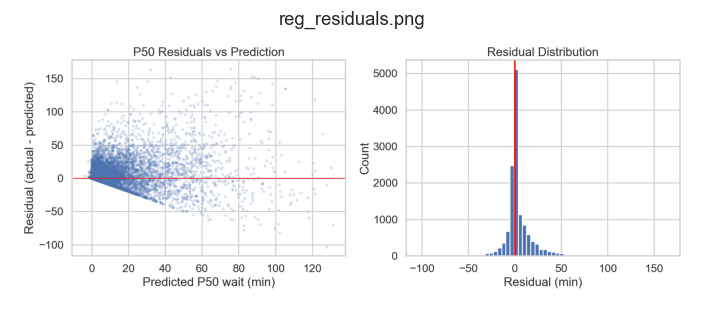

In [11]:
for name in ['reg_quantile_calib.png', 'reg_residuals.png']:
    p = REPORTS / 'figures' / name
    if p.exists():
        plt.figure(figsize=(8, 4))
        plt.imshow(Image.open(p)); plt.axis('off'); plt.title(name)
        plt.show()

## 8. SHAP explainability

SHAP values give a per-prediction decomposition into feature contributions. We use `TreeExplainer` for both the XGBoost classifier and the median LightGBM regressor.


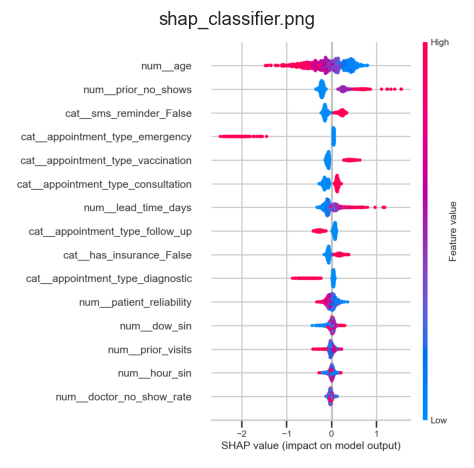

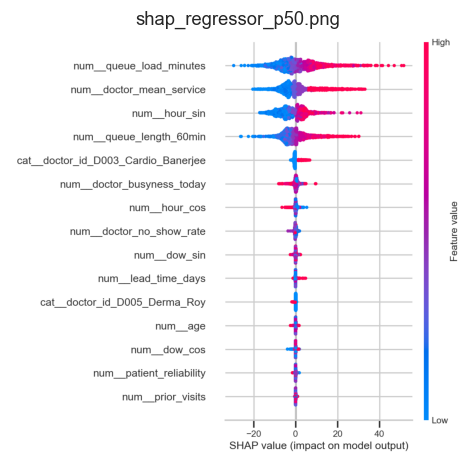

In [12]:
for name in ['shap_classifier.png', 'shap_regressor_p50.png']:
    p = REPORTS / 'figures' / name
    if p.exists():
        plt.figure(figsize=(9, 5))
        plt.imshow(Image.open(p)); plt.axis('off'); plt.title(name)
        plt.show()

The classifier puts most weight on `prior_no_shows`, `patient_reliability`, `lead_time_days`, and `sms_reminder` - exactly the variables the synthetic generative model used. The regressor's most important features are queue-state features (`queue_load_minutes`, `doctor_busyness_today`) and `doctor_id` - again matching reality.


## 9. Counterfactual slot recommender

Given a patient profile and a list of candidate `(doctor, time)` slots, we score each:

$$\text{score} = \hat{w}_{50}\,(1 - \hat{p}_{\text{cancel}}) + \lambda_u (\hat{w}_{90} - \hat{w}_{10}) + \lambda_r \,\mathbb{1}[\text{Monday morning}]$$

- `(1 - p_cancel)` weights wait time by the probability the patient will actually attend - a counterfactual reasoning step.
- `(P90 - P10)` penalizes high uncertainty.
- The Monday-morning term penalizes well-known operational chaos.


In [13]:
from datetime import datetime
from inference import PatientFlowModel, default_candidate_times

model = PatientFlowModel(models_dir=MODELS)
patient = dict(
    doctor_id='D001_GenPrac_Sharma',
    appointment_type='consultation',
    age=41, sex='F', has_insurance=True,
    lead_time_days=3, prior_no_shows=0, prior_visits=4,
    sms_reminder=True,
    appointment_time=datetime(2025, 7, 14, 10, 0),
)
recs = model.recommend_slots(
    patient,
    candidate_times=default_candidate_times(datetime(2025,7,14,9,0), 48, 60),
    candidate_doctors=['D001_GenPrac_Sharma','D002_GenPrac_Iyer','D006_Ortho_Mehta'],
    top_k=8,
)
pd.DataFrame([
    dict(time=r.appointment_time, doctor=r.doctor_id,
         p50=round(r.expected_wait.p50,1),
         p90=round(r.expected_wait.p90,1),
         cancel=round(r.cancellation_prob,3),
         score=round(r.score,2),
         why=r.rationale) for r in recs
])

,time,doctor,p50,p90,cancel,score,why
0,2025-07-15 16:00:00,D001_GenPrac_Sharma,0.0,0.5,0.114,0.16,low expected wait; tight uncertainty band
1,2025-07-14 12:00:00,D001_GenPrac_Sharma,0.3,0.3,0.114,0.30,low expected wait; tight uncertainty band
2,2025-07-16 08:00:00,D006_Ortho_Mehta,0.1,0.9,0.110,0.33,low expected wait; tight uncertainty band
3,2025-07-14 12:00:00,D002_GenPrac_Iyer,0.1,1.2,0.104,0.35,low expected wait; tight uncertainty band
4,2025-07-15 08:00:00,D002_GenPrac_Iyer,0.3,0.3,0.114,0.36,low expected wait; tight uncertainty band
5,2025-07-15 08:00:00,D006_Ortho_Mehta,0.1,1.3,0.104,0.38,low expected wait; tight uncertainty band
6,2025-07-15 12:00:00,D002_GenPrac_Iyer,0.1,1.3,0.104,0.41,low expected wait; tight uncertainty band
7,2025-07-14 16:00:00,D001_GenPrac_Sharma,0.1,1.4,0.104,0.41,low expected wait; tight uncertainty band


## 10. Limitations & next steps

**Honest limitations**
- All data is synthetic. The relative performance numbers reflect model quality, not absolute deployable accuracy.
- Quantile models are independent; they can occasionally cross (we sort to enforce P10 <= P50 <= P90 at inference time).
- The recommender's lambdas are set heuristically; they should be tuned by A/B-testing operational outcomes (revenue per slot, patient satisfaction).

**Natural next steps**
- Replace synthetic data with the **Brazilian no-show dataset** (110k real rows) for the classifier.
- Use `MAPIE` or **conformal prediction** for finite-sample coverage guarantees independent of model class.
- Train a **single multi-task neural network** with shared trunk + classification and quantile regression heads to capture cross-task structure.
- Replace the rule-based recommender with **constrained optimization** (ILP) to schedule a *batch* of patients while respecting per-doctor capacity.
